# Practical 9 — Decision Tree Classification

**Aim:** Build a decision tree to classify breast tumours, inspect the learned rules, control over-fitting with depth, and
evaluate with train/test split and k-fold CV (Accuracy, TP, TN, FP, FN, Error, Recall, Specificity, F1, AUC).

**Dataset:** Breast Cancer Wisconsin (Diagnostic) – UCI, bundled with scikit-learn.

**Idea:** A tree asks a sequence of yes/no questions of the form *"feature ≤ threshold?"*.
At each node the algorithm (CART) tries **every feature and every possible threshold** and keeps the split that gives
the largest drop in **impurity**. Gini impurity of a node = 1 − Σ pₖ² (0 = pure node). It recurses on the two children
until the nodes are pure or a stopping rule (e.g. `max_depth`) applies. A prediction = follow the questions down to a leaf.
Trees need **no feature scaling**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

pd.set_option("display.precision", 4)

## Evaluation helpers (shared by all classification practicals)
The syllabus asks us to report **Accuracy, TP, TN, FP, FN, Error, Recall, Specificity, F1-score and AUC**.
* `classification_metrics` – builds the confusion matrix `[[TN, FP], [FN, TP]]` and derives every metric from it
  (formulas are in the docstring).
* `kfold_evaluate` – manual **stratified k-fold cross-validation**: for every fold it clones the model, trains on
  k-1 folds, tests on the held-out fold and records all metrics, so you can see each intermediate result.

In [2]:
from sklearn.base import clone
from sklearn.metrics import (confusion_matrix, roc_auc_score, roc_curve,
                             ConfusionMatrixDisplay, classification_report)
from sklearn.model_selection import StratifiedKFold


def classification_metrics(y_true, y_pred, y_score=None):
    """Return all metrics required by the syllabus for a BINARY problem (positive class = 1).

    Accuracy    = (TP+TN)/(TP+TN+FP+FN)      Error       = 1 - Accuracy
    Recall      = TP/(TP+FN)  (sensitivity)  Specificity = TN/(TN+FP)
    Precision   = TP/(TP+FP)                 F1          = 2*P*R/(P+R)
    AUC         = area under the ROC curve (needs a continuous score, not the hard label)
    """
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    specificity = tn / (tn + fp) if (tn + fp) else 0.0
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    auc = roc_auc_score(y_true, y_score) if y_score is not None else np.nan
    return pd.Series({"TP": tp, "TN": tn, "FP": fp, "FN": fn, "Accuracy": accuracy,
                      "Error": 1 - accuracy, "Recall": recall, "Specificity": specificity,
                      "Precision": precision, "F1": f1, "AUC": auc})


def get_score(model, X):
    """Continuous score used for AUC: P(class=1) if available, otherwise the SVM-style decision value."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def kfold_evaluate(model, X, y, k=5, seed=42):
    """Stratified k-fold CV. Returns (per-fold table, mean/std summary)."""
    X, y = np.asarray(X), np.asarray(y)
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
    rows = []
    for fold, (tr, te) in enumerate(skf.split(X, y), start=1):
        m = clone(model).fit(X[tr], y[tr])                 # fresh, untrained copy each fold
        r = classification_metrics(y[te], m.predict(X[te]), get_score(m, X[te]))
        r.name = f"Fold {fold}"
        rows.append(r)
        print(f"Fold {fold}: train={len(tr)}, test={len(te)}, accuracy={r['Accuracy']:.4f}, AUC={r['AUC']:.4f}")
    folds = pd.DataFrame(rows)
    return folds, pd.DataFrame({"mean": folds.mean(), "std": folds.std()})


def plot_cm_roc(model, X_test, y_test, title=""):
    """Confusion matrix + ROC curve side by side."""
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax[0], cmap="Blues",
                                          display_labels=["Benign (0)", "Malignant (1)"])
    ax[0].set_title(f"Confusion matrix {title}")
    fpr, tpr, _ = roc_curve(y_test, get_score(model, X_test))
    ax[1].plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc_score(y_test, get_score(model, X_test)):.3f}")
    ax[1].plot([0, 1], [0, 1], "k--", label="Chance")
    ax[1].set(xlabel="False Positive Rate (1 - Specificity)", ylabel="True Positive Rate (Recall)",
              title=f"ROC curve {title}")
    ax[1].legend(); plt.tight_layout(); plt.show()

## Step 1 — Load and inspect the data

In [3]:
data = load_breast_cancer(as_frame=True)
X_df = data.data                                  # 30 numeric features
y_s = (data.target == 0).astype(int)              # flip so that 1 = MALIGNANT (the "positive" class), 0 = benign
df = X_df.assign(target=y_s)

print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("\nClass balance (1 = malignant):")
print(y_s.value_counts().rename({0: "benign", 1: "malignant"}))
df.head()

Shape: (569, 31)
Missing values: 0

Class balance (1 = malignant):
target
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189,1
1,20.57,17.77,132.90,1326.0,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890,1
2,19.69,21.25,130.00,1203.0,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876,1
3,11.42,20.38,77.58,386.1,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730,1
4,20.29,14.34,135.10,1297.0,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768,1


## Step 2 — Train / test split

In [4]:
X, y = X_df.values, y_s.values
feature_names = list(X_df.columns)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (455, 30) Test: (114, 30)


## Step 3 — How the root split is chosen (manual search)
1. Compute the Gini impurity of the whole training set (the root).
2. For each feature, sort its values; candidate thresholds are the **mid-points** between consecutive distinct values.
3. For each candidate split compute the **weighted Gini of the two children**:
   `(n_left/n)·G_left + (n_right/n)·G_right`.
4. Keep the (feature, threshold) with the lowest weighted Gini (= largest impurity decrease).

In [5]:
def gini(labels):
    if len(labels) == 0:
        return 0.0
    p = np.bincount(labels, minlength=2) / len(labels)
    return 1 - np.sum(p ** 2)

root_gini = gini(y_train)
print(f"Step 3.1  root: {len(y_train)} samples, class counts [benign, malignant] = {np.bincount(y_train)}, Gini = {root_gini:.4f}")

best = {"gini": np.inf}
per_feature_best = []
n = len(y_train)
for j in range(X_train.shape[1]):
    order = np.argsort(X_train[:, j])
    xs, ys = X_train[order, j], y_train[order]
    thresholds = (xs[:-1] + xs[1:]) / 2                        # mid-points
    feat_best = np.inf
    for t in np.unique(thresholds):
        left, right = ys[xs <= t], ys[xs > t]
        w = len(left) / n * gini(left) + len(right) / n * gini(right)
        if w < feat_best: feat_best, feat_t = w, t
        if w < best["gini"]: best = {"gini": w, "feature": j, "threshold": t}
    per_feature_best.append((feature_names[j], feat_t, feat_best))

top = pd.DataFrame(per_feature_best, columns=["feature", "best_threshold", "weighted_gini"]).sort_values("weighted_gini").head(5)
print("Step 3.2-3.3  best split found for each feature (5 best shown):")
display(top)
print(f"Step 3.4  winner → '{feature_names[best['feature']]} <= {best['threshold']:.4f}' "
      f"with weighted Gini {best['gini']:.4f} (decrease = {root_gini - best['gini']:.4f})")

Step 3.1  root: 455 samples, class counts [benign, malignant] = [285 170], Gini = 0.4681


Step 3.2-3.3  best split found for each feature (5 best shown):


,feature,best_threshold,weighted_gini
22,worst perimeter,112.8000,0.1307
20,worst radius,16.7950,0.1343
23,worst area,874.8500,0.1414
27,worst concave points,0.1417,0.1456
7,mean concave points,0.0559,0.1457


Step 3.4  winner → 'worst perimeter <= 112.8000' with weighted Gini 0.1307 (decrease = 0.3373)


## Step 4 — Fit scikit-learn's `DecisionTreeClassifier` (unrestricted) and compare the root

In [6]:
full_tree = DecisionTreeClassifier(criterion="gini", random_state=42).fit(X_train, y_train)
root_feat = full_tree.tree_.feature[0]
print(f"sklearn root split: '{feature_names[root_feat]} <= {full_tree.tree_.threshold[0]:.4f}'")
print(f"manual  root split: '{feature_names[best['feature']]} <= {best['threshold']:.4f}'")
print("\nUnrestricted tree → depth:", full_tree.get_depth(), "| leaves:", full_tree.get_n_leaves(),
      "| train accuracy:", round(full_tree.score(X_train, y_train), 4), "| test accuracy:", round(full_tree.score(X_test, y_test), 4))
print("(100 % train accuracy with lower test accuracy is the signature of over-fitting)")

sklearn root split: 'worst perimeter <= 112.8000'
manual  root split: 'worst perimeter <= 112.8000'

Unrestricted tree → depth: 8 | leaves: 24 | train accuracy: 1.0 | test accuracy: 0.9298
(100 % train accuracy with lower test accuracy is the signature of over-fitting)


## Step 5 — Controlling complexity: sweep `max_depth`

,train_acc,test_acc,CV_acc
max_depth,,,
1,0.9297,0.8772,0.9209
2,0.9538,0.9211,0.9275
3,0.9670,0.9035,0.9319
4,0.9824,0.9123,0.9253
5,0.9868,0.9211,0.9341
6,0.9934,0.9211,0.9319
7,0.9956,0.9386,0.9429
8,1.0000,0.9298,0.9319
9,1.0000,0.9298,0.9363


Best depth by 5-fold CV on the training set: 7


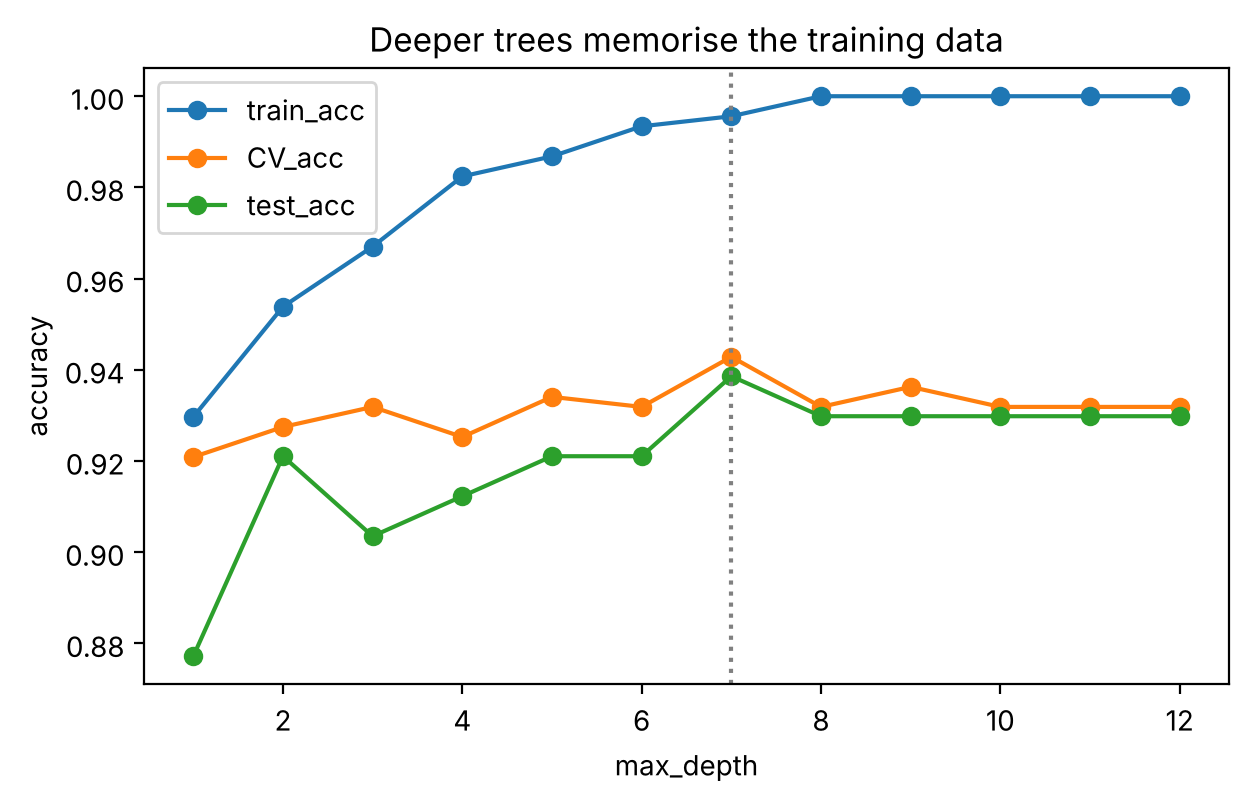

In [7]:
rows = []
for d in range(1, 13):
    t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    rows.append({"max_depth": d, "train_acc": t.score(X_train, y_train), "test_acc": t.score(X_test, y_test),
                 "CV_acc": cross_val_score(t, X_train, y_train, cv=5).mean()})
sweep = pd.DataFrame(rows).set_index("max_depth")
display(sweep.round(4))
best_depth = int(sweep["CV_acc"].idxmax())
print("Best depth by 5-fold CV on the training set:", best_depth)

plt.figure(figsize=(7, 4))
for c in ["train_acc", "CV_acc", "test_acc"]:
    plt.plot(sweep.index, sweep[c], "o-", label=c)
plt.axvline(best_depth, color="gray", ls=":"); plt.xlabel("max_depth"); plt.ylabel("accuracy")
plt.title("Deeper trees memorise the training data"); plt.legend(); plt.show()

## Step 6 — Final (pruned) tree: rules and picture

|--- worst perimeter <= 112.80
|   |--- worst concave points <= 0.16
|   |   |--- mean area <= 696.25
|   |   |   |--- worst smoothness <= 0.18
|   |   |   |   |--- worst perimeter <= 102.40
|   |   |   |   |   |--- truncated branch of depth 3
|   |   |   |   |--- worst perimeter >  102.40
|   |   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- worst smoothness >  0.18
|   |   |   |   |--- mean perimeter <= 66.70
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- mean perimeter >  66.70
|   |   |   |   |   |--- class: 1
|   |   |--- mean area >  696.25
|   |   |   |--- mean texture <= 19.23
|   |   |   |   |--- class: 0
|   |   |   |--- mean texture >  19.23
|   |   |   |   |--- class: 1
|   |--- worst concave points >  0.16
|   |   |--- worst texture <= 24.78
|   |   |   |--- mean compactness <= 0.16
|   |   |   |   |--- class: 0
|   |   |   |--- mean compactness >  0.16
|   |   |   |   |--- class: 1
|   |   |--- worst texture >  24.78
|   |   |   |--- class: 1
|--- 

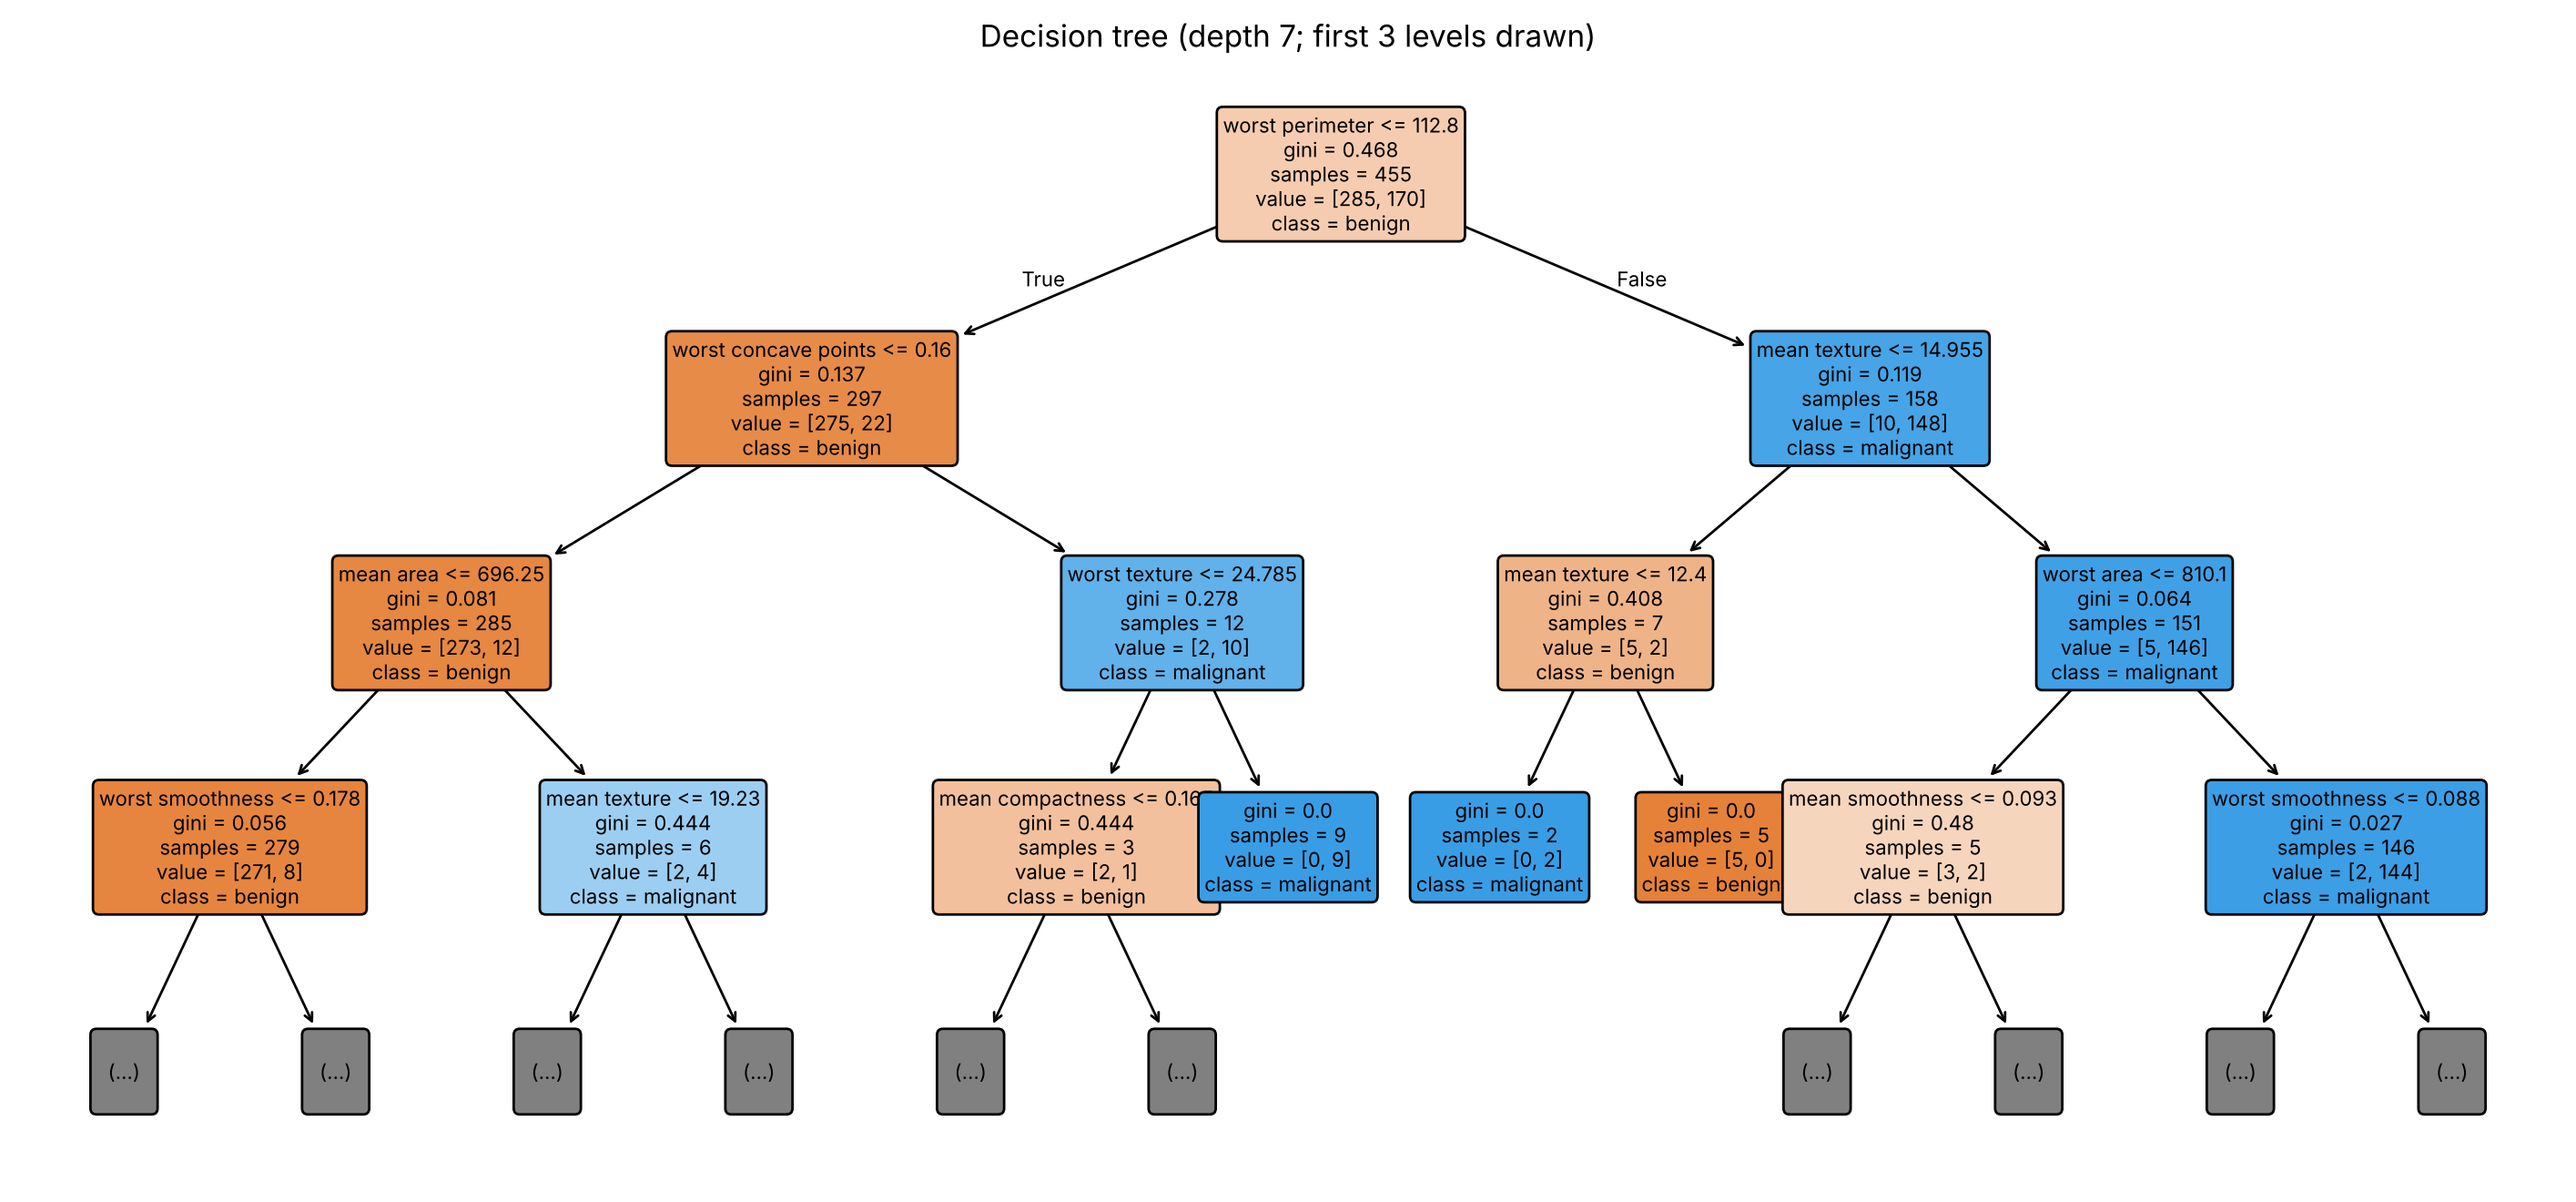

In [8]:
tree = DecisionTreeClassifier(max_depth=best_depth, random_state=42).fit(X_train, y_train)
print(export_text(tree, feature_names=feature_names, max_depth=4))

plt.figure(figsize=(18, 8))
plot_tree(tree, feature_names=feature_names, class_names=["benign", "malignant"], filled=True, rounded=True,
          max_depth=3, fontsize=8)
plt.title(f"Decision tree (depth {best_depth}; first 3 levels drawn)"); plt.show()

### Following one test sample down the tree
`decision_path` returns the nodes visited; at each one we print the question and the answer.

In [9]:
x0 = X_test[0].reshape(1, -1)
node_path = tree.decision_path(x0).indices
leaf = tree.apply(x0)[0]
for node in node_path:
    if node == leaf:
        counts = tree.tree_.value[node][0]
        print(f"Leaf {node}: class distribution {counts.round(3)} → predict {tree.classes_[counts.argmax()]}")
    else:
        f, t = tree.tree_.feature[node], tree.tree_.threshold[node]
        ans = "yes" if x0[0, f] <= t else "no"
        print(f"Node {node}: is {feature_names[f]} ({x0[0, f]:.3f}) <= {t:.3f}?  → {ans}")
print("True label:", y_test[0], "| tree predicts:", tree.predict(x0)[0])

Node 0: is worst perimeter (83.740) <= 112.800?  → yes
Node 1: is worst concave points (0.090) <= 0.160?  → yes
Node 2: is mean area (403.300) <= 696.250?  → yes
Node 3: is worst smoothness (0.155) <= 0.178?  → yes
Node 4: is worst perimeter (83.740) <= 102.400?  → yes
Node 5: is area error (10.500) <= 47.035?  → yes
Node 6: is worst texture (15.970) <= 33.350?  → yes
Leaf 7: class distribution [1. 0.] → predict 0
True label: 0 | tree predicts: 0


## Step 7 — Feature importance
Importance of a feature = total (weighted) Gini decrease obtained from the splits that use it, normalised to sum to 1.

,importance
worst perimeter,0.7374
worst concave points,0.0686
mean texture,0.0558
worst smoothness,0.0414
mean area,0.0228
worst area,0.0158
mean smoothness,0.0114
mean perimeter,0.0114


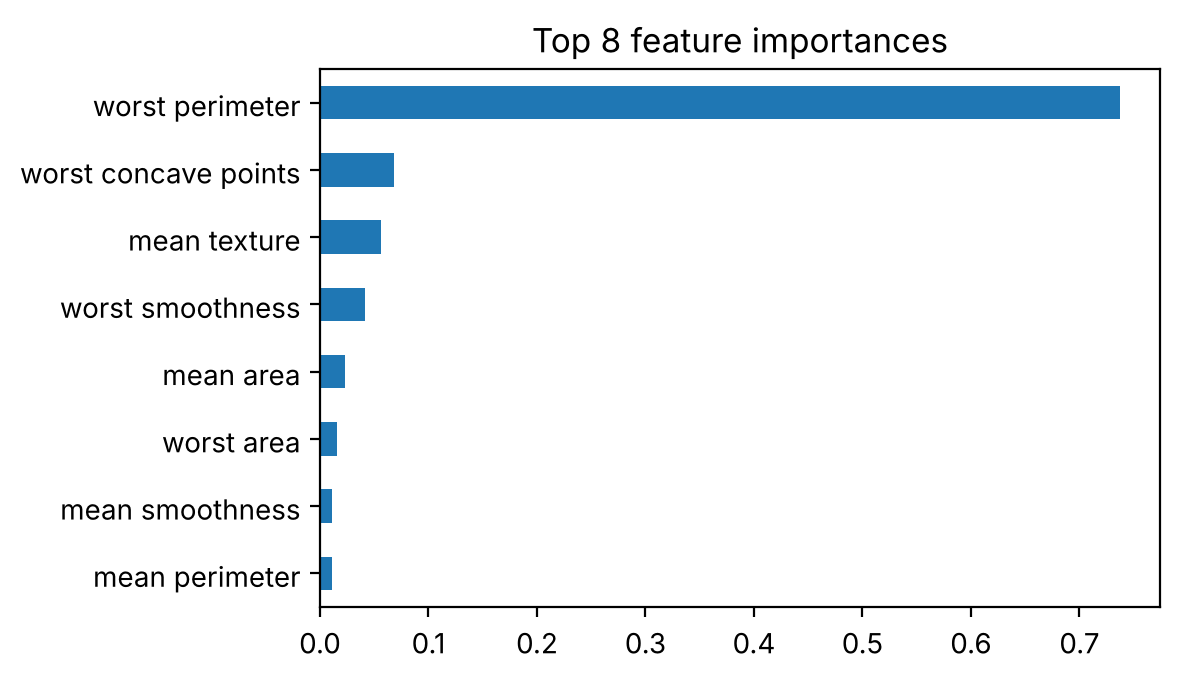

In [10]:
imp = pd.Series(tree.feature_importances_, index=feature_names).sort_values(ascending=False)
display(imp.head(8).to_frame("importance"))
imp.head(8)[::-1].plot.barh(figsize=(6, 3.5), title="Top 8 feature importances"); plt.tight_layout(); plt.show()

## Step 8 — Evaluation on the hold-out test set

,Train,Test
TP,168.0000,37.0000
TN,285.0000,70.0000
FP,0.0000,2.0000
FN,2.0000,5.0000
Accuracy,0.9956,0.9386
Error,0.0044,0.0614
Recall,0.9882,0.8810
Specificity,1.0000,0.9722
Precision,1.0000,0.9487
F1,0.9941,0.9136


              precision    recall  f1-score   support

      benign       0.93      0.97      0.95        72
   malignant       0.95      0.88      0.91        42

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



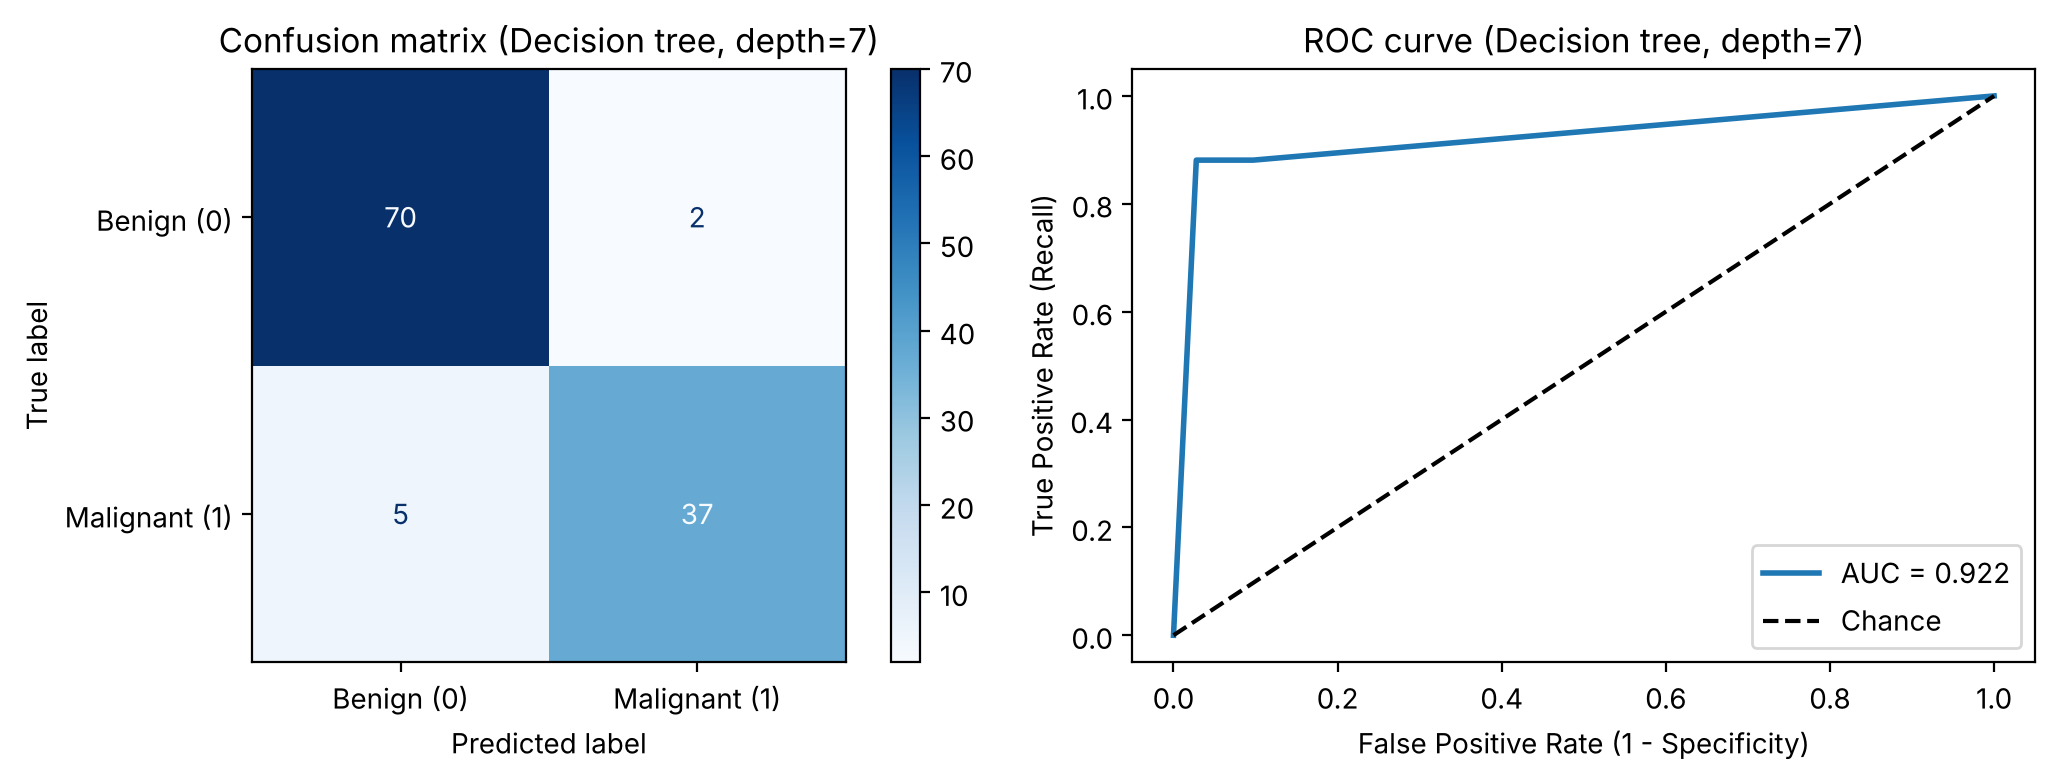

In [11]:
y_pred = tree.predict(X_test)
test_m = classification_metrics(y_test, y_pred, tree.predict_proba(X_test)[:, 1])
train_m = classification_metrics(y_train, tree.predict(X_train), tree.predict_proba(X_train)[:, 1])
display(pd.DataFrame({"Train": train_m, "Test": test_m}).round(4))
print(classification_report(y_test, y_pred, target_names=["benign", "malignant"]))
plot_cm_roc(tree, X_test, y_test, title=f"(Decision tree, depth={best_depth})")

## Step 9 — k-fold cross-validation (k = 5)

In [12]:
folds, summary = kfold_evaluate(DecisionTreeClassifier(max_depth=best_depth, random_state=42), X, y, k=5)
print()
display(folds.round(4)); display(summary.round(4))

Fold 1: train=455, test=114, accuracy=0.9386, AUC=0.9402
Fold 2: train=455, test=114, accuracy=0.8772, AUC=0.8510
Fold 3: train=455, test=114, accuracy=0.8860, AUC=0.8700
Fold 4: train=455, test=114, accuracy=0.9386, AUC=0.9415
Fold 5: train=456, test=113, accuracy=0.9292, AUC=0.9193



,TP,TN,FP,FN,Accuracy,Error,Recall,Specificity,Precision,F1,AUC
Fold 1,41.0,66.0,5.0,2.0,0.9386,0.0614,0.9535,0.9296,0.8913,0.9213,0.9402
Fold 2,32.0,68.0,3.0,11.0,0.8772,0.1228,0.7442,0.9577,0.9143,0.8205,0.8510
Fold 3,34.0,67.0,5.0,8.0,0.8860,0.1140,0.8095,0.9306,0.8718,0.8395,0.8700
Fold 4,40.0,67.0,5.0,2.0,0.9386,0.0614,0.9524,0.9306,0.8889,0.9195,0.9415
Fold 5,37.0,68.0,3.0,5.0,0.9292,0.0708,0.8810,0.9577,0.9250,0.9024,0.9193


,mean,std
TP,36.8000,3.8341
TN,67.2000,0.8367
FP,4.2000,1.0954
FN,5.6000,3.9115
Accuracy,0.9139,0.0299
Error,0.0861,0.0299
Recall,0.8681,0.0913
Specificity,0.9412,0.0151
Precision,0.8983,0.0213
F1,0.8807,0.0473


## Step 10 — Summary

In [13]:
display(pd.DataFrame({"Hold-out test": test_m, "5-fold CV mean": summary["mean"]}).round(4))

,Hold-out test,5-fold CV mean
TP,37.0000,36.8000
TN,70.0000,67.2000
FP,2.0000,4.2000
FN,5.0000,5.6000
Accuracy,0.9386,0.9139
Error,0.0614,0.0861
Recall,0.8810,0.8681
Specificity,0.9722,0.9412
Precision,0.9487,0.8983
F1,0.9136,0.8807


### Conclusion
* The tree learns human-readable if/else rules; the manual search reproduces the root split chosen by scikit-learn (feature + threshold from the largest Gini decrease).
* An unrestricted tree fits the training data perfectly but generalises worse; limiting `max_depth` (chosen by CV) gives a simpler and more robust tree.
* Only a handful of features carry most of the importance (in this run the root feature *worst perimeter* alone accounts for roughly three quarters – see Step 7).
* A single tree has a high variance (small data changes can change the tree) – ensembles such as Random Forests reduce this.